# Do wandering black holes merge?

Uses the `SM5_DFD_3_TNG` wandering-BH catalogue written by
[`py_files/wandering_bh_catalog.py`](../py_files/wandering_bh_catalog.py) and the
simulation's `blackhole_mergers.hdf5` to answer two questions:

1. **Wanderer + nuclear BH.** How many wanderers merge with the nuclear BH of
   their own galaxy, with what mass ratios, and at what rate as a function of
   redshift?
2. **Wanderer + wanderer.** How many wanderers merge with another wanderer, and
   where? Is the merger off-centre, by how much, what is the separation when
   they merge, and how much extra delay should we expect before a real
   coalescence?

**Definitions**

- A BH is **wandering** when it sits outside its host's stellar half-mass
  radius $R_{1/2,\star}$, and the **nuclear BH** is the one closest to the
  host's potential minimum while inside $R_{1/2,\star}$. Both come from the
  catalogue's `is_wandering` and `is_closest_to_centre` flags.
- A merger is classified by the state of both BHs at the **last snapshot
  before the merger** (`snap_before`).
- The simulation merges two BHs once they are closer than
  $a_{\rm merge} = 2 \times 0.5$ ckpc/h $= a/h$ physical kpc (0.25 kpc at
  $z = 5$, 0.74 kpc at $z = 1$, 1.48 kpc at $z = 0$) and pass a rough
  boundedness test. The merger log stores no position or separation, so
  $a_{\rm merge}$ is the upper limit on the separation at the moment of merging.
- **Seed–seed mergers** (both BHs still at the $1.5\times10^5\,M_\odot$ seed
  mass) are a seeding artefact at $q = 1$ and are excluded by default
  (`EXCLUDE_SEED_SEED`).

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import h5py
from astropy.cosmology import FlatLambdaCDM

from cosmo_sim_tools import brahma

sys.path.append('../py_files/')
import plot_style as ps
from wandering_bh_catalog import bh_particle_start

ps.set_style('paper', font_scale=1.15)

SIM_NAME = 'SM5_DFD_3_TNG'
SIM_FILE = ('/orange/lblecha/aklantbhowmick/GAS_BASED_SEED_MODEL_UNIFORM_RUNS/'
            f'L12p5n512/AREPO/{SIM_NAME}/')
DATA_DIR = Path('/orange/lblecha/pranavsatheesh/wandering_bhs/Data')
CATALOGUE = DATA_DIR / f'wandering_bh_{SIM_NAME}.hdf5'
BH_ID_CACHE = DATA_DIR / f'wandering_bh_ids_{SIM_NAME}.npy'
FIGURE_DIR = Path('../figures')

EXCLUDE_SEED_SEED = True

# run parameters, from parameters-usedvalues
SEED_MASS_CODE = 1e-5
DYNAMICAL_SEED_MASS_CODE = 2.4e-4
MERGING_DISTANCE_CKPC_H = 2 * 0.5        # MinDistanceForMergingBlackHoles x SofteningComoving[0]

GRAVITATIONAL_CONSTANT = 4.30091e-6      # kpc (km/s)^2 / Msun
MYR_PER_KPC_PER_KMS = 977.79             # one kpc / (km/s) in Myr

COLORS = ['#2a78d6', '#eb6834', '#1baf7a']

catalogue = h5py.File(CATALOGUE, 'r')
hubble_param = float(catalogue.attrs['HubbleParam'])
box_size_ckpc_h = float(catalogue.attrs['BoxSize_ckpc_over_h'])
box_volume_cmpc3 = (box_size_ckpc_h / 1e3 / hubble_param)**3
cosmology = FlatLambdaCDM(H0=100 * hubble_param, Om0=0.3089)

snapshots = catalogue['snapshot/snap'][:].astype(np.int64)
snapshot_redshift = catalogue['snapshot/redshift'][:].astype(np.float64)
snapshot_scale_factor = 1 / (1 + snapshot_redshift)
snapshot_age_myr = cosmology.age(snapshot_redshift).to('Myr').value
age_today_myr = cosmology.age(0).to('Myr').value

seed_mass_msun = SEED_MASS_CODE * 1e10 / hubble_param
dynamical_seed_mass_msun = DYNAMICAL_SEED_MASS_CODE * 1e10 / hubble_param
print(f'box volume {box_volume_cmpc3:.0f} cMpc^3, seed mass {seed_mass_msun:.3g} Msun, '
      f'dynamical seed mass {dynamical_seed_mass_msun:.3g} Msun')

box volume 6292 cMpc^3, seed mass 1.48e+05 Msun, dynamical seed mass 3.54e+06 Msun


## Catalogue BHs and their ParticleIDs

The merger log identifies BHs by ParticleID, which the catalogue does not
store. A subhalo's `/bh` rows are a contiguous slice of the group-ordered BH
particle array, so the IDs are recovered with `bh_particle_start` and checked
against the catalogue masses, then cached.

In [2]:
bh = {name: catalogue[f'bh/{name}'][:] for name in
      ['snap', 'subhalo_index', 'subhalo_row', 'mass_msun', 'r_kpc', 'r_over_stellar_halfrad',
       'is_wandering', 'is_closest_to_centre', 'pos_ckpc_over_h']}


def recover_bh_ids():
    """ParticleID of every /bh row, checked against the catalogue's BH masses."""
    bh_ids = np.zeros(len(bh['snap']), dtype=np.int64)
    for snapshot in np.unique(bh['snap']):
        rows = np.flatnonzero(bh['snap'] == snapshot)
        subhalos = brahma.groupcat.loadSubhalos_postprocessed(
            SIM_FILE, int(snapshot), fields=['SubhaloLenType', 'SubhaloGrNr'])
        groups = brahma.groupcat.loadHalos_postprocessed(
            SIM_FILE, int(snapshot), fields=['GroupLenType', 'GroupFirstSub'])
        bh_start = bh_particle_start(
            np.asarray(groups['GroupLenType'], dtype=np.int64)[:, 5],
            np.asarray(groups['GroupFirstSub'], dtype=np.int64),
            np.asarray(subhalos['SubhaloLenType'], dtype=np.int64)[:, 5],
            np.asarray(subhalos['SubhaloGrNr'], dtype=np.int64))
        particles = brahma.snapshot.loadSubset_groupordered(
            SIM_FILE, int(snapshot), 5, fields=['ParticleIDs', 'BH_Mass'])

        # position of each row within its subhalo's slice
        subhalo_rows = bh['subhalo_row'][rows]
        rank_in_subhalo = np.arange(len(rows)) - np.searchsorted(subhalo_rows, subhalo_rows)
        particle_rows = bh_start[bh['subhalo_index'][rows]] + rank_in_subhalo

        particle_mass_msun = particles['BH_Mass'][particle_rows] * 1e10 / hubble_param
        assert np.allclose(particle_mass_msun, bh['mass_msun'][rows], rtol=1e-5), \
            f'snap {snapshot}: recovered BHs do not match the catalogue masses'
        bh_ids[rows] = particles['ParticleIDs'][particle_rows]
    np.save(BH_ID_CACHE, bh_ids)
    return bh_ids


bh['id'] = np.load(BH_ID_CACHE) if BH_ID_CACHE.exists() else recover_bh_ids()

# IDs are below 1e12, so snap * 1e12 + id is a unique (snapshot, BH) key
ID_STRIDE = 10**12
catalogue_key = bh['snap'].astype(np.int64) * ID_STRIDE + bh['id']
key_order = np.argsort(catalogue_key)
sorted_catalogue_key = catalogue_key[key_order]


def catalogue_row(snapshot, bh_id):
    """Row in /bh of `bh_id` at `snapshot`, or -1 when the catalogue does not hold it."""
    query = np.asarray(snapshot, dtype=np.int64) * ID_STRIDE + np.asarray(bh_id)
    position = np.clip(np.searchsorted(sorted_catalogue_key, query), 0, len(key_order) - 1)
    return np.where(sorted_catalogue_key[position] == query, key_order[position], -1)


ever_wandering_ids = np.unique(bh['id'][bh['is_wandering']])
print(f"{len(bh['id']):,} catalogue rows, {len(np.unique(bh['id'])):,} distinct BHs, "
      f"{len(ever_wandering_ids):,} of them wandering at least once")

151,386 catalogue rows, 22,587 distinct BHs, 14,277 of them wandering at least once


## The merger log

Duplicate rows (same time and IDs, written twice) are dropped, and each merger
is placed in the snapshot gap it falls in, `snap_before < merger <= snap_after`.

In [3]:
with h5py.File(SIM_FILE + 'blackhole_mergers.hdf5', 'r') as merger_file:
    mergers = {name: merger_file[name][:]
               for name in ['ScaleFactor', 'BH_ID1', 'BH_ID2', 'BH_Mass1', 'BH_Mass2']}

_, unique_rows = np.unique(
    np.column_stack([mergers['ScaleFactor'], mergers['BH_ID1'], mergers['BH_ID2']]),
    axis=0, return_index=True)
time_order = unique_rows[np.argsort(mergers['ScaleFactor'][unique_rows], kind='stable')]
mergers = {name: value[time_order] for name, value in mergers.items()}
n_mergers = len(time_order)

merger_scale_factor = mergers['ScaleFactor']
merger_redshift = 1 / merger_scale_factor - 1
merger_age_myr = cosmology.age(merger_redshift).to('Myr').value
mass1_msun = mergers['BH_Mass1'] * 1e10 / hubble_param
mass2_msun = mergers['BH_Mass2'] * 1e10 / hubble_param
mass_ratio = np.minimum(mass1_msun, mass2_msun) / np.maximum(mass1_msun, mass2_msun)
merging_distance_kpc = MERGING_DISTANCE_CKPC_H * merger_scale_factor / hubble_param

gap = np.searchsorted(snapshot_scale_factor, merger_scale_factor, side='right') - 1
snap_before = snapshots[gap]
snap_after = snapshots[gap + 1]
is_seed_seed = (mergers['BH_Mass1'] < 1.01 * SEED_MASS_CODE) & (mergers['BH_Mass2'] < 1.01 * SEED_MASS_CODE)

print(f'{n_mergers:,} distinct mergers between z = {merger_redshift.max():.1f} and '
      f'{merger_redshift.min():.3f}; {is_seed_seed.sum():,} ({is_seed_seed.mean():.0%}) are seed-seed')

15,558 distinct mergers between z = 16.5 and 0.002; 5,876 (38%) are seed-seed


## Who does each wanderer merge with?

Both BHs are looked up at `snap_before`. A merger with at least one wandering
progenitor goes into one of three classes:

| class | partner at `snap_before` |
|---|---|
| wanderer + nuclear BH | the nuclear BH of the same subhalo |
| wanderer + wanderer | another wanderer in the same subhalo |
| wanderer + other | anything else: a non-nuclear BH inside $R_{1/2,\star}$, a BH in another subhalo, or a BH the catalogue does not hold (seeded in the gap, or in a starless host) |

In [4]:
row1 = catalogue_row(snap_before, mergers['BH_ID1'])
row2 = catalogue_row(snap_before, mergers['BH_ID2'])
found1, found2 = row1 >= 0, row2 >= 0
wandering1 = found1 & bh['is_wandering'][np.maximum(row1, 0)]
wandering2 = found2 & bh['is_wandering'][np.maximum(row2, 0)]
nuclear1 = found1 & ~wandering1 & bh['is_closest_to_centre'][np.maximum(row1, 0)]
nuclear2 = found2 & ~wandering2 & bh['is_closest_to_centre'][np.maximum(row2, 0)]
same_host = found1 & found2 & (bh['subhalo_row'][np.maximum(row1, 0)] == bh['subhalo_row'][np.maximum(row2, 0)])

has_wanderer = wandering1 | wandering2
kept = ~is_seed_seed if EXCLUDE_SEED_SEED else np.ones(n_mergers, dtype=bool)
wanderer_nuclear = kept & same_host & ((wandering1 & nuclear2) | (wandering2 & nuclear1))
wanderer_wanderer = kept & same_host & wandering1 & wandering2
wanderer_other = kept & has_wanderer & ~wanderer_nuclear & ~wanderer_wanderer

print(f'mergers with a wandering progenitor: {has_wanderer.sum():,} including seed-seed, '
      f'{(has_wanderer & kept).sum():,} kept')
for name, selection in [('wanderer + nuclear BH', wanderer_nuclear),
                        ('wanderer + wanderer', wanderer_wanderer),
                        ('wanderer + other', wanderer_other)]:
    print(f'  {name:22} {selection.sum():6,}  ({selection.sum() / (has_wanderer & kept).sum():.0%})')

mergers with a wandering progenitor: 4,370 including seed-seed, 3,095 kept
  wanderer + nuclear BH   2,226  (72%)
  wanderer + wanderer       271  (9%)
  wanderer + other          598  (19%)


## 1. Wanderers merging with the nuclear BH

### How many, and at what mass ratio?

$q = M_2 / M_1 \le 1$ from the masses in the merger log. An EMRI needs
$q \lesssim 10^{-4}$, which a seed only reaches against a
$\gtrsim 10^{9}\,M_\odot$ primary, more massive than any BH in this box, so
the low-$q$ end here is the IMRI regime $10^{-4} \lesssim q \lesssim 10^{-2}$.

In [5]:
wanderer_mass_msun = np.where(wandering1, mass1_msun, mass2_msun)
partner_mass_msun = np.where(wandering1, mass2_msun, mass1_msun)
nuclear_merging_ids = np.unique(np.where(wandering1, mergers['BH_ID1'], mergers['BH_ID2'])[wanderer_nuclear])

print(f'{wanderer_nuclear.sum():,} wanderer + nuclear BH mergers, involving '
      f'{len(nuclear_merging_ids):,} distinct wanderers '
      f'({len(nuclear_merging_ids) / len(ever_wandering_ids):.0%} of all BHs that ever wander)')
print(f'the wanderer is the heavier BH in {np.mean(wanderer_mass_msun[wanderer_nuclear] > partner_mass_msun[wanderer_nuclear]):.0%} of them')
print(f'q: median {np.median(mass_ratio[wanderer_nuclear]):.2f}, '
      f'minimum {mass_ratio[wanderer_nuclear].min():.1e}')

Q_EDGES = [1e-4, 1e-2, 1e-1, 1.0 + 1e-9]
Q_LABELS = ['IMRI   1e-4 - 0.01', 'minor  0.01 - 0.1', 'major  0.1 - 1']
REDSHIFT_RANGES = {'z > 3': (3, np.inf), '1 < z < 3': (1, 3), 'z < 1': (0, 1)}
print(f'\n{"":20}' + ''.join(f'{name:>12}' for name in REDSHIFT_RANGES) + f'{"all z":>10}')
for low_q, high_q, label in zip(Q_EDGES[:-1], Q_EDGES[1:], Q_LABELS):
    in_q_bin = wanderer_nuclear & (mass_ratio >= low_q) & (mass_ratio < high_q)
    counts = [np.sum(in_q_bin & (merger_redshift >= low) & (merger_redshift < high))
              for low, high in REDSHIFT_RANGES.values()]
    print(f'{label:20}' + ''.join(f'{count:12d}' for count in counts) + f'{in_q_bin.sum():10d}')

2,226 wanderer + nuclear BH mergers, involving 2,209 distinct wanderers (15% of all BHs that ever wander)
the wanderer is the heavier BH in 3% of them
q: median 0.25, minimum 2.6e-04

                           z > 3   1 < z < 3       z < 1     all z
IMRI   1e-4 - 0.01             2          35          83       120
minor  0.01 - 0.1             60         163         137       360
major  0.1 - 1               876         557         313      1746


### Merger rate versus redshift

Two rates per snapshot gap: the **comoving rate density**, mergers per Gyr per
cMpc³ (comparable to other simulations and to GW forecasts), and the **rate
per wanderer**, mergers per Gyr divided by the number of wanderers at
`snap_before` (what fraction of the wandering population merges per Gyr).
Wanderer + wanderer mergers are included for comparison with section 2.

In [6]:
gap_duration_gyr = np.diff(snapshot_age_myr) / 1e3
gap_redshift = 0.5 * (snapshot_redshift[:-1] + snapshot_redshift[1:])
n_wandering_at_snapshot = np.bincount(np.searchsorted(snapshots, bh['snap'][bh['is_wandering']]),
                                      minlength=len(snapshots))[:-1]
has_wanderers = n_wandering_at_snapshot >= 10

merger_classes = {'wanderer + nuclear BH': wanderer_nuclear, 'wanderer + wanderer': wanderer_wanderer}
mergers_in_gap = {name: np.bincount(gap[selection], minlength=len(gap_duration_gyr))
                  for name, selection in merger_classes.items()}
rate_density = {name: counts / gap_duration_gyr / box_volume_cmpc3 for name, counts in mergers_in_gap.items()}
rate_per_wanderer = {name: counts / np.maximum(n_wandering_at_snapshot, 1) / gap_duration_gyr
                     for name, counts in mergers_in_gap.items()}

nuclear_counts = mergers_in_gap['wanderer + nuclear BH']
print(f'{"z_before":>8} {"gap/Gyr":>8} {"N_wand":>7} {"N_merge":>8} {"median q":>9} '
      f'{"/Gyr/cMpc^3":>12} {"/Gyr/wanderer":>14}')
for index in np.flatnonzero(has_wanderers):
    in_gap = wanderer_nuclear & (gap == index)
    median_q = np.median(mass_ratio[in_gap]) if in_gap.any() else np.nan
    print(f'{snapshot_redshift[index]:8.2f} {gap_duration_gyr[index]:8.3f} {n_wandering_at_snapshot[index]:7d} '
          f'{nuclear_counts[index]:8d} {median_q:9.2f} '
          f'{rate_density["wanderer + nuclear BH"][index]:12.2e} {rate_per_wanderer["wanderer + nuclear BH"][index]:14.3f}')

z_before  gap/Gyr  N_wand  N_merge  median q  /Gyr/cMpc^3  /Gyr/wanderer
   14.99    0.026      18        0       nan     0.00e+00          0.000
   14.03    0.033      50        0       nan     0.00e+00          0.000
   13.00    0.040     110        0       nan     0.00e+00          0.000
   11.98    0.048     226        1      0.50     3.34e-03          0.093
   10.98    0.057     458        9      0.50     2.51e-02          0.345
   10.00    0.072     756        8      0.50     1.75e-02          0.146
    9.00    0.093    1351       29      0.50     4.98e-02          0.232
    8.01    0.124    1965       65      0.50     8.31e-02          0.266
    7.01    0.168    2418      108      0.50     1.02e-01          0.266
    6.01    0.246    2847      192      0.50     1.24e-01          0.275
    5.00    0.363    3268      223      0.33     9.76e-02          0.188
    4.01    0.605    3632      303      0.32     7.96e-02          0.138
    3.01    1.140    4317      318      0.24     4.

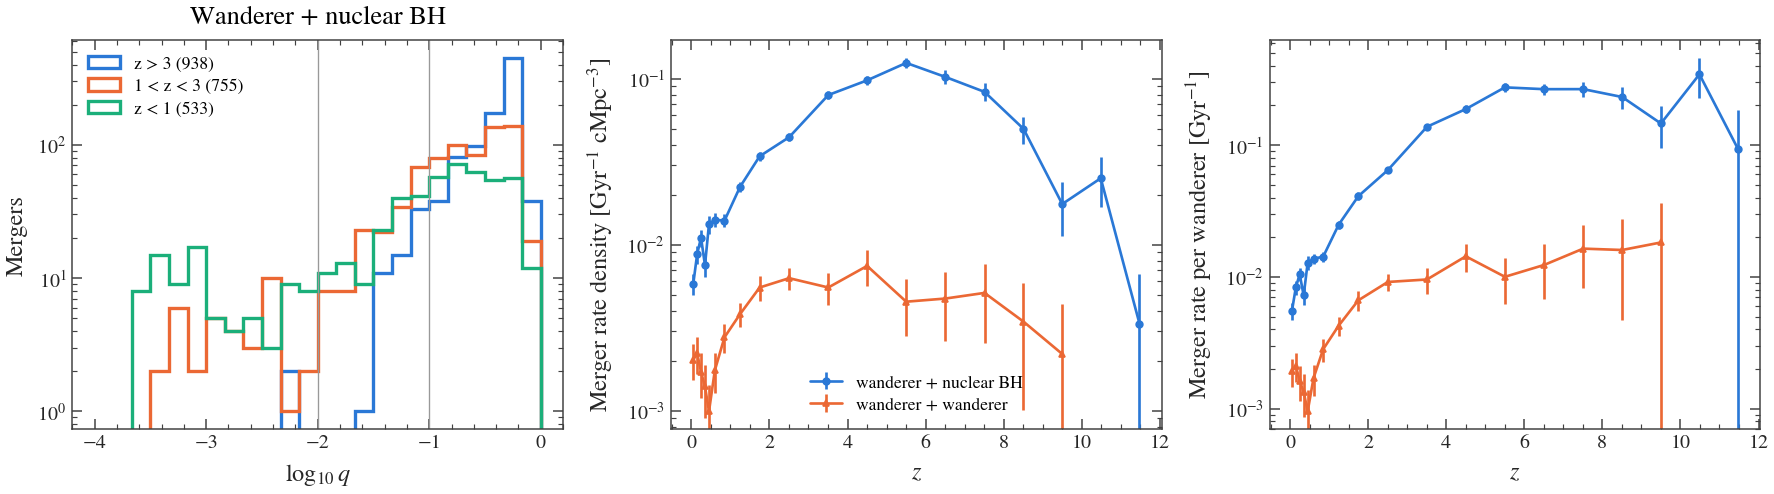

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.4))

log_q_bins = np.linspace(-4, 0, 25)
for color, (name, (low, high)) in zip(COLORS, REDSHIFT_RANGES.items()):
    in_range = wanderer_nuclear & (merger_redshift >= low) & (merger_redshift < high)
    axes[0].hist(np.log10(mass_ratio[in_range]), bins=log_q_bins, histtype='step', color=color,
                 linewidth=2, label=f'{name} ({in_range.sum()})')
for edge in Q_EDGES[1:-1]:
    axes[0].axvline(np.log10(edge), color='0.6', linewidth=0.8)
axes[0].set(xlabel=r'$\log_{10} q$', ylabel='Mergers', yscale='log',
            title='Wanderer + nuclear BH')
axes[0].legend(frameon=False, fontsize='small', loc='upper left')

for color, marker, name in zip(COLORS, ['o', '^'], merger_classes):
    counts = mergers_in_gap[name][has_wanderers]
    shown = counts > 0
    for ax, rate in [(axes[1], rate_density[name]), (axes[2], rate_per_wanderer[name])]:
        rate = rate[has_wanderers]
        ax.errorbar(gap_redshift[has_wanderers][shown], rate[shown],
                    yerr=rate[shown] / np.sqrt(counts[shown]), color=color, marker=marker,
                    markersize=4, capsize=0, label=name)
axes[1].set(ylabel=r'Merger rate density [Gyr$^{-1}$ cMpc$^{-3}$]')
axes[2].set(ylabel=r'Merger rate per wanderer [Gyr$^{-1}$]')
for ax in axes[1:]:
    ax.set(xlabel=r'$z$', yscale='log')
axes[1].legend(frameon=False, fontsize='small', loc='lower center')
fig.tight_layout()
fig.savefig(FIGURE_DIR / f'wandering_bh_nuclear_mergers_{SIM_NAME}.pdf')
plt.show()

### Paper figures: merger mass ratio, and the masses of wandering, central and nuclear BHs

Wandering BHs sit outside $R_{1/2,\star}$, central BHs are all those inside it, and the nuclear BH is the
central BH closest to the potential minimum. Each catalogue row is one BH at one snapshot, and each
histogram is normalised to the BHs it holds.

In [ ]:
redshift_colors = ps.sequential_colors(len(REDSHIFT_RANGES), cmap='plasma', low=0.05, high=0.75)
redshift_linestyles = ps.line_styles(len(REDSHIFT_RANGES))
log_q_bins = np.linspace(-4, 0, 25)

fig, ax = plt.subplots(figsize=(5.2, 4.2))
for color, linestyle, (name, (low, high)) in zip(redshift_colors, redshift_linestyles, REDSHIFT_RANGES.items()):
    in_range = wanderer_nuclear & (merger_redshift >= low) & (merger_redshift < high)
    ax.hist(np.log10(mass_ratio[in_range]), bins=log_q_bins, histtype='step', color=color,
            linestyle=linestyle, linewidth=2, label=f'${name}$ ({in_range.sum()})')
ax.set(xlabel=r'$\log_{10} q$', ylabel='Wanderer + nuclear BH mergers', yscale='log', xlim=(-4, 0))
ax.legend(loc='upper left')
fig.savefig(FIGURE_DIR / f'wandering_bh_nuclear_merger_mass_ratio_{SIM_NAME}.pdf')
plt.show()

In [ ]:
bh_redshift = snapshot_redshift[np.searchsorted(snapshots, bh['snap'])]
bh_populations = {
    'Wandering': bh['is_wandering'],
    'Central': ~bh['is_wandering'],
    'Nuclear': ~bh['is_wandering'] & bh['is_closest_to_centre'],
}
# BH masses are quantised in multiples of the seed mass at the low end, so the
# 0.25 dex bins are centred on the seed mass to avoid alternating empty bins
log_mass_bins = np.log10(seed_mass_msun) - 0.125 + 0.25 * np.arange(17)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), sharex=True, sharey=True)
for ax, (title, in_population) in zip(axes, bh_populations.items()):
    for color, linestyle, (name, (low, high)) in zip(redshift_colors, redshift_linestyles, REDSHIFT_RANGES.items()):
        selected = in_population & (bh_redshift >= low) & (bh_redshift < high)
        ax.hist(np.log10(bh['mass_msun'][selected]), bins=log_mass_bins, histtype='step', color=color,
                linestyle=linestyle, linewidth=2, weights=np.full(selected.sum(), 1 / selected.sum()),
                label=f'${name}$')
    ax.set(xlabel=r'$\log_{10}\, M_{\rm BH}\ [M_\odot]$', yscale='log', title=title)
axes[0].set(ylabel='Fraction of BHs')
axes[-1].legend(loc='upper right')
fig.tight_layout()
fig.savefig(FIGURE_DIR / f'wandering_central_nuclear_bh_masses_{SIM_NAME}.pdf')
plt.show()

In [ ]:
host_stellar_mass_msun = catalogue['subhalo/stellar_mass_msun'][:][bh['subhalo_row']]
STELLAR_MASS_RANGES = {r'$10^{7}$–$10^{8}$': (1e7, 1e8),
                       r'$10^{8}$–$10^{9}$': (1e8, 1e9),
                       r'$10^{9}$–$10^{10}$': (1e9, 1e10)}
stellar_mass_colors = ps.sequential_colors(len(STELLAR_MASS_RANGES))
stellar_mass_linestyles = ps.line_styles(len(STELLAR_MASS_RANGES))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), sharex=True, sharey=True)
for ax, (title, in_population) in zip(axes, bh_populations.items()):
    for color, linestyle, (name, (low, high)) in zip(stellar_mass_colors, stellar_mass_linestyles,
                                                     STELLAR_MASS_RANGES.items()):
        # normalised to every BH in the M_star bin, so wandering + central sum to 1
        in_stellar_mass_bin = (host_stellar_mass_msun >= low) & (host_stellar_mass_msun < high)
        selected = in_population & in_stellar_mass_bin
        ax.hist(np.log10(bh['mass_msun'][selected]), bins=log_mass_bins, histtype='step', color=color,
                linestyle=linestyle, linewidth=2, weights=np.full(selected.sum(), 1 / in_stellar_mass_bin.sum()),
                label=name)
    ax.set(xlabel=r'$\log_{10}\, M_{\rm BH}\ [M_\odot]$', yscale='log', title=title)
axes[0].set(ylabel=r'Fraction of all BHs in the $M_\star$ bin')
axes[-1].legend(title=r'$M_\star\ [M_\odot]$', loc='upper right')
fig.tight_layout()
fig.savefig(FIGURE_DIR / f'wandering_central_nuclear_bh_masses_mstar_bins_{SIM_NAME}.pdf')
plt.show()

## 2. Wanderers merging with another wanderer

### How many?

In [8]:
pair = np.flatnonzero(wanderer_wanderer)
pair_ids = np.unique(np.concatenate([mergers['BH_ID1'][pair], mergers['BH_ID2'][pair]]))
pair_secondary_mass_msun = np.minimum(mass1_msun, mass2_msun)[pair]
pair_primary_mass_msun = np.maximum(mass1_msun, mass2_msun)[pair]

print(f'{len(pair):,} wanderer + wanderer mergers, involving {len(pair_ids):,} distinct wanderers '
      f'({len(pair_ids) / len(ever_wandering_ids):.1%} of all BHs that ever wander)')
print(f'redshift: median {np.median(merger_redshift[pair]):.1f}, 10-90% {np.percentile(merger_redshift[pair], 10):.1f}'
      f' - {np.percentile(merger_redshift[pair], 90):.1f}')
print(f'q: median {np.median(mass_ratio[pair]):.2f}; secondary mass: median {np.median(pair_secondary_mass_msun):.2e} Msun, '
      f'{np.mean(pair_secondary_mass_msun < 1.01 * seed_mass_msun):.0%} still at the seed mass')

271 wanderer + wanderer mergers, involving 470 distinct wanderers (3.3% of all BHs that ever wander)
redshift: median 1.5, 10-90% 0.2 - 4.3
q: median 0.33; secondary mass: median 1.49e+05 Msun, 49% still at the seed mass


### Where do they merge?

The merger log has no position, so the site is read off a snapshot. `BH_ID1`
survives the merger and was within $a_{\rm merge}$ of its partner when it
happened, so the site is the remnant's position at `snap_after`. If `BH_ID1` is
swallowed again before `snap_after`, the BH that swallowed it is followed
instead. The merger is **off-centre** if that position is outside
$R_{1/2,\star}$.

`snap_before` cannot give the site: both BHs are wanderers there by
selection, so every site would be off-centre. The `snap_after` position errs
the other way, since the remnant may sink between the merger and the snapshot,
so the off-centre fraction below is a lower limit.

In [9]:
swallowed_in_merger = {bh_id: index for index, bh_id in enumerate(mergers['BH_ID2'])}
remnant_id = mergers['BH_ID1'][pair].copy()
for position, index in enumerate(pair):
    current = index
    later = swallowed_in_merger.get(remnant_id[position], -1)
    while later > current and gap[later] == gap[index]:
        remnant_id[position] = mergers['BH_ID1'][later]
        current = later
        later = swallowed_in_merger.get(remnant_id[position], -1)
site_row = catalogue_row(snap_after[pair], remnant_id)
assert np.all(site_row >= 0), 'a remnant is missing from the catalogue at snap_after'
time_to_site_myr = snapshot_age_myr[gap[pair] + 1] - merger_age_myr[pair]

site_offset_kpc = bh['r_kpc'][site_row]
site_r_over_halfrad = bh['r_over_stellar_halfrad'][site_row]
is_offcentre = site_r_over_halfrad > 1

print(f'remnant followed through a later merger in the same gap: {np.sum(remnant_id != mergers["BH_ID1"][pair])}')
print(f'time from merger to snap_after: median {np.median(time_to_site_myr):.0f} Myr, '
      f'90th percentile {np.percentile(time_to_site_myr, 90):.0f} Myr')
print(f'at snap_before BH_ID1 sits at median r/R_1/2 = {np.median(bh["r_over_stellar_halfrad"][row1[pair]]):.2f} '
      f'({np.median(bh["r_kpc"][row1[pair]]):.2f} kpc)')
print(f'off-centre at snap_after (r > R_1/2): {is_offcentre.sum()} of {len(pair)} ({is_offcentre.mean():.0%})')
for name, selection in [('off-centre', is_offcentre), ('centred', ~is_offcentre)]:
    print(f'  {name:10} r_site: median {np.median(site_offset_kpc[selection]):.2f} kpc '
          f'(10-90% {np.percentile(site_offset_kpc[selection], 10):.2f} - {np.percentile(site_offset_kpc[selection], 90):.2f}), '
          f'median r/R_1/2 {np.median(site_r_over_halfrad[selection]):.2f}')

remnant followed through a later merger in the same gap: 37
time from merger to snap_after: median 341 Myr, 90th percentile 1011 Myr
at snap_before BH_ID1 sits at median r/R_1/2 = 1.65 (2.51 kpc)
off-centre at snap_after (r > R_1/2): 93 of 271 (34%)
  off-centre r_site: median 4.34 kpc (10-90% 0.98 - 12.23), median r/R_1/2 2.79
  centred    r_site: median 0.11 kpc (10-90% 0.00 - 1.43), median r/R_1/2 0.10


### Separations, and is the pair bound when it merges?

The separation at the moment of merging is below $a_{\rm merge}$; the merger
log gives nothing finer. The separation at `snap_before` shows how far apart
the two were at the last resolved snapshot.

At offset $r$ in its host, a pair is held together only inside its Jacobi
radius $r_J = r\,\big(M_{\rm pair} / 3 M_{\rm host}(<r)\big)^{1/3}$. If
$a_{\rm merge} > r_J$, the host's tide would pull the two apart again: the
simulation merged two wanderers that passed within $a_{\rm merge}$ of each
other, not a bound binary. $M_{\rm host}(<r)$ is the sum of three Hernquist
spheres (gas, dark matter, stars) with Subfind's masses and 3D half-mass radii
($r_{1/2} = (1 + \sqrt2)\,a$) for the site's host.

In [10]:
HOST_COMPONENTS = [0, 1, 4]              # gas, dark matter, stars

site_snap = bh['snap'][site_row]
site_subhalo = bh['subhalo_index'][site_row]
host_mass_msun = np.zeros((len(pair), len(HOST_COMPONENTS)))
host_halfrad_kpc = np.zeros((len(pair), len(HOST_COMPONENTS)))
for snapshot in np.unique(site_snap):
    here = site_snap == snapshot
    subhalos = brahma.groupcat.loadSubhalos_postprocessed(
        SIM_FILE, int(snapshot), fields=['SubhaloMassType', 'SubhaloHalfmassRadType'])
    scale_factor = snapshot_scale_factor[np.searchsorted(snapshots, snapshot)]
    host_mass_msun[here] = (np.asarray(subhalos['SubhaloMassType'])[site_subhalo[here]][:, HOST_COMPONENTS]
                            * 1e10 / hubble_param)
    host_halfrad_kpc[here] = (np.asarray(subhalos['SubhaloHalfmassRadType'])[site_subhalo[here]][:, HOST_COMPONENTS]
                              * scale_factor / hubble_param)


def host_enclosed_mass(radius_kpc):
    """Mass in Msun inside radius_kpc (one radius per pair) of each pair's host."""
    scale_length = host_halfrad_kpc / (1 + np.sqrt(2))
    return np.sum(host_mass_msun * (radius_kpc[:, None] / (radius_kpc[:, None] + scale_length))**2, axis=1)


separation_vector = bh['pos_ckpc_over_h'][row1[pair]] - bh['pos_ckpc_over_h'][row2[pair]]
separation_vector -= box_size_ckpc_h * np.round(separation_vector / box_size_ckpc_h)   # minimum image
separation_before_kpc = (np.linalg.norm(separation_vector, axis=1)
                         * snapshot_scale_factor[gap[pair]] / hubble_param)
pair_merging_distance_kpc = merging_distance_kpc[pair]

# a site at the potential minimum has r ~ 0, inside the resolution limit anyway
site_radius_kpc = np.maximum(site_offset_kpc, pair_merging_distance_kpc)
host_mass_inside_site = host_enclosed_mass(site_radius_kpc)
jacobi_radius_true_kpc = site_radius_kpc * ((mass1_msun + mass2_msun)[pair] / (3 * host_mass_inside_site))**(1 / 3)
dynamical_pair_mass_msun = (np.maximum(mass1_msun, dynamical_seed_mass_msun)
                            + np.maximum(mass2_msun, dynamical_seed_mass_msun))[pair]
jacobi_radius_dynamical_kpc = site_radius_kpc * (dynamical_pair_mass_msun / (3 * host_mass_inside_site))**(1 / 3)

print(f'separation at merger: below a_merge = {np.percentile(pair_merging_distance_kpc, 10):.2f} - '
      f'{np.percentile(pair_merging_distance_kpc, 90):.2f} kpc (10-90%), median {np.median(pair_merging_distance_kpc):.2f} kpc')
print(f'separation at snap_before: median {np.median(separation_before_kpc):.2f} kpc, 10-90% '
      f'{np.percentile(separation_before_kpc, 10):.2f} - {np.percentile(separation_before_kpc, 90):.2f} kpc, '
      f'median {np.median(separation_before_kpc / pair_merging_distance_kpc):.1f} x a_merge')
print(f'\noff-centre pairs: Jacobi radius median {np.median(jacobi_radius_true_kpc[is_offcentre]) * 1e3:.0f} pc (true masses)')
print(f'  a_merge > r_J with true masses:      {np.mean(pair_merging_distance_kpc[is_offcentre] > jacobi_radius_true_kpc[is_offcentre]):.0%}')
print(f'  a_merge > r_J with dynamical masses: {np.mean(pair_merging_distance_kpc[is_offcentre] > jacobi_radius_dynamical_kpc[is_offcentre]):.0%}')

separation at merger: below a_merge = 0.28 - 1.28 kpc (10-90%), median 0.59 kpc
separation at snap_before: median 3.75 kpc, 10-90% 1.10 - 9.76 kpc, median 6.4 x a_merge

off-centre pairs: Jacobi radius median 95 pc (true masses)
  a_merge > r_J with true masses:      100%
  a_merge > r_J with dynamical masses: 97%


### How much extra delay?

Since the pair is not bound when the simulation merges it, the two BHs still
have to sink to the host centre by dynamical friction before they can form a
real binary. The lighter BH sinks slowest, so the delay is its Chandrasekhar
friction time on a circular orbit from the merger site (Binney & Tremaine
2008, eq. 8.13),

$$t_{\rm DF} = \frac{1.17}{\ln\Lambda}\,\frac{r^2 v_c}{G M_2}, \qquad
v_c^2 = \frac{G M_{\rm host}(<r)}{r}, \qquad \ln\Lambda = \ln\!\left(1 + \frac{r v_c^2}{G M_2}\right),$$

with $r = \max(r_{\rm site}, a_{\rm merge})$. It is computed with the true
mass and with the $3.5\times10^6\,M_\odot$ dynamical-mass floor the simulation
used for friction. Binary hardening and GW inspiral come on top of this, so
it is a lower limit on the delay.

In [11]:
circular_speed_kms = np.sqrt(GRAVITATIONAL_CONSTANT * host_mass_inside_site / site_radius_kpc)
time_left_myr = age_today_myr - merger_age_myr[pair]

friction_delay_gyr = {}
for label, sinking_mass_msun in [('true mass', pair_secondary_mass_msun),
                                 ('dynamical mass', np.maximum(pair_secondary_mass_msun, dynamical_seed_mass_msun))]:
    coulomb_log = np.log(1 + site_radius_kpc * circular_speed_kms**2 / (GRAVITATIONAL_CONSTANT * sinking_mass_msun))
    friction_delay_gyr[label] = (1.17 * site_radius_kpc**2 * circular_speed_kms
                                 / (GRAVITATIONAL_CONSTANT * sinking_mass_msun * coulomb_log)
                                 * MYR_PER_KPC_PER_KMS / 1e3)

print(f'{"":12} {"":15} {"N":>4} {"median t_DF/Gyr":>16} {"10-90% /Gyr":>16} {"done by z=0":>12}')
for name, selection in [('off-centre', is_offcentre), ('centred', ~is_offcentre), ('all', np.ones(len(pair), dtype=bool))]:
    for label, delay in friction_delay_gyr.items():
        low, high = np.percentile(delay[selection], [10, 90])
        print(f'{name:12} {label:15} {selection.sum():4d} {np.median(delay[selection]):16.2f} '
              f'{f"{low:.2f} - {high:.0f}":>16} {np.mean(delay[selection] * 1e3 < time_left_myr[selection]):12.0%}')

                                N  median t_DF/Gyr      10-90% /Gyr  done by z=0
off-centre   true mass         93           491.89     29.59 - 3938           3%
off-centre   dynamical mass    93            32.99       1.99 - 271          18%
centred      true mass        178             4.63        0.55 - 60          59%
centred      dynamical mass   178             0.37         0.05 - 4          92%
all          true mass        271            19.43      0.74 - 1378          40%
all          dynamical mass   271             1.34        0.06 - 82          66%


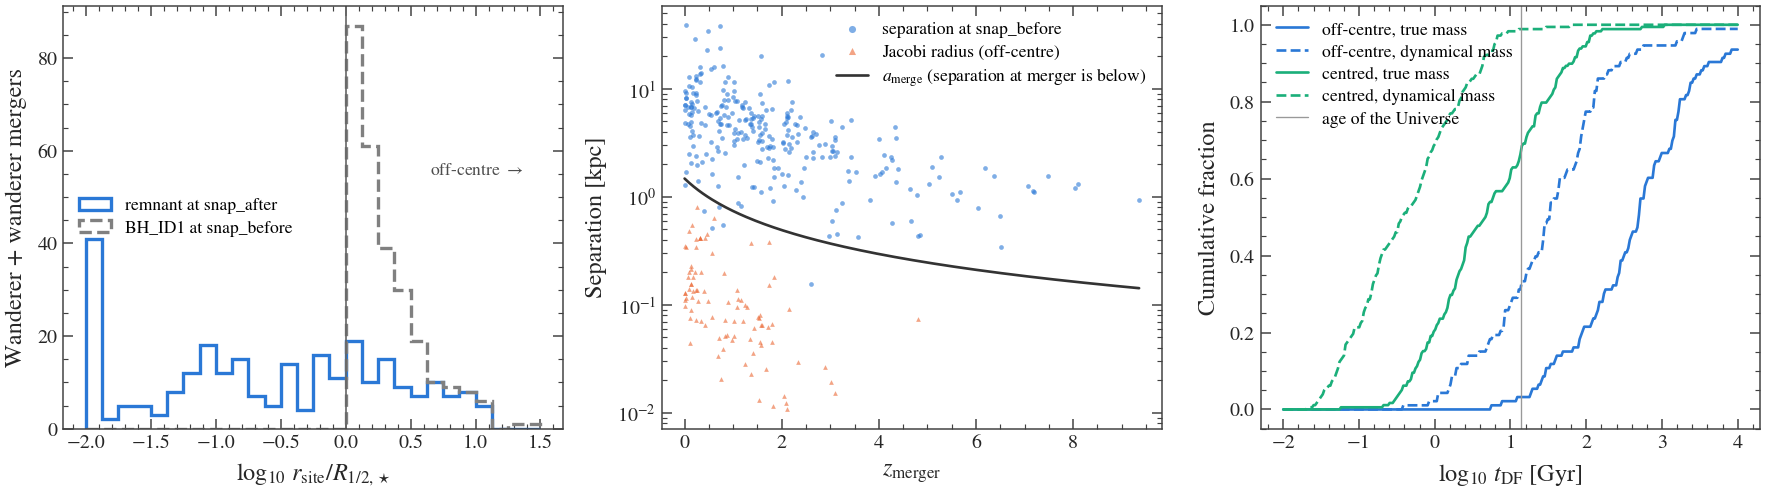

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.4))

R_FLOOR = 1e-2   # sites at the potential minimum (r ~ 0) go into the left-most bin
log_r_bins = np.linspace(-2, 1.5, 29)
for color, dash, label, r_over_halfrad in [
        (COLORS[0], '-', 'remnant at snap_after', site_r_over_halfrad),
        ('0.5', '--', 'BH_ID1 at snap_before', bh['r_over_stellar_halfrad'][row1[pair]])]:
    axes[0].hist(np.log10(np.maximum(r_over_halfrad, R_FLOOR)), bins=log_r_bins, histtype='step',
                 color=color, linestyle=dash, linewidth=2, label=label)
axes[0].axvline(0, color='0.4', linewidth=1)
axes[0].text(0.65, 0.6, r'off-centre $\rightarrow$', transform=axes[0].get_xaxis_transform(),
             fontsize='small', color='0.3')
axes[0].set(xlabel=r'$\log_{10}\, r_{\rm site} / R_{1/2,\star}$', ylabel='Wanderer + wanderer mergers')
axes[0].legend(frameon=False, fontsize='small', loc='center left')

redshift_grid = np.linspace(0, merger_redshift[pair].max(), 200)
axes[1].scatter(merger_redshift[pair], separation_before_kpc, s=8, color=COLORS[0], alpha=0.6,
                label='separation at snap_before')
axes[1].scatter(merger_redshift[pair][is_offcentre], jacobi_radius_true_kpc[is_offcentre], s=8, marker='^',
                color=COLORS[1], alpha=0.6, label='Jacobi radius (off-centre)')
axes[1].plot(redshift_grid, MERGING_DISTANCE_CKPC_H / (1 + redshift_grid) / hubble_param, color='0.2',
             label=r'$a_{\rm merge}$ (separation at merger is below)')
axes[1].set(xlabel=r'$z_{\rm merger}$', ylabel='Separation [kpc]', yscale='log')
axes[1].legend(frameon=False, fontsize='small', markerscale=1.5)

log_delay_grid = np.linspace(-2, 4, 300)
for color, name, selection in [(COLORS[0], 'off-centre', is_offcentre), (COLORS[2], 'centred', ~is_offcentre)]:
    for dash, (label, delay) in zip(['-', '--'], friction_delay_gyr.items()):
        cumulative = np.mean(np.log10(delay[selection])[:, None] <= log_delay_grid[None, :], axis=0)
        axes[2].plot(log_delay_grid, cumulative, color=color, linestyle=dash,
                     label=f'{name}, {label}')
axes[2].axvline(np.log10(age_today_myr / 1e3), color='0.6', linewidth=0.8, label='age of the Universe')
axes[2].set(xlabel=r'$\log_{10}\, t_{\rm DF}$ [Gyr]', ylabel='Cumulative fraction')
axes[2].legend(frameon=False, fontsize='small', loc='upper left')

fig.tight_layout()
fig.savefig(FIGURE_DIR / f'wandering_bh_pair_mergers_{SIM_NAME}.pdf')
plt.show()

## Summary

Numbers from the run of 2026-10-30, seed–seed mergers excluded. Of the
15,558 distinct mergers, 3,095 have a wandering progenitor: 72% are with the
nuclear BH, 9% with another wanderer, and 19% with something else.

**1. Wanderer + nuclear BH**

- **How many:** 2,226 mergers, involving 2,209 distinct wanderers, which is
  15% of the 14,277 BHs that ever wander. The wanderer is the lighter BH in
  97% of them.
- **Mass ratios:** median $q = 0.25$; 78% are major ($q > 0.1$), 16% minor
  and 5% IMRI-like ($10^{-4}$–$10^{-2}$). There are no EMRIs: the smallest
  ratio is $q = 2.6\times10^{-4}$. $q$ falls with time, from a median of 0.5
  at $z > 6$, where the nuclear BH is itself only a few seeds, to ~0.15 at
  $z < 1$. 83 of the 120 IMRIs happen at $z < 1$.
- **Rate vs redshift:** the comoving rate density peaks at
  ~0.12 Gyr⁻¹ cMpc⁻³ at $z \approx 5.5$ and falls ~20× to
  ~0.006 Gyr⁻¹ cMpc⁻³ by $z \approx 0.1$. Per wanderer, ~25% merge with
  their nucleus per Gyr at $z = 6$–8, falling to ~1% per Gyr at $z < 0.5$.

**2. Wanderer + wanderer**

- **How many:** 271 mergers (median $z = 1.5$), involving 470 distinct
  wanderers (3.3% of all wanderers). The rate density is roughly flat at
  ~$5\times10^{-3}$ Gyr⁻¹ cMpc⁻³ for $z \approx 2$–8 and drops to
  ~$2\times10^{-3}$ at $z < 1$. Median $q = 0.33$; half of the lighter BHs
  are still at the seed mass.
- **Where:** about a third (93, or 34%) are still off-centre at the first
  snapshot after the merger (median 340 Myr later), at a median 4.3 kpc
  (1–12 kpc, $2.8\,R_{1/2,\star}$). This is a lower limit, since the remnant
  can sink in between. The rest sit at the centre (median 0.1 kpc).
- **Separation at merger:** below $a_{\rm merge}$, which is 0.3–1.3 kpc for
  these mergers (median 0.6 kpc). At the last snapshot before the merger
  they were a median 3.8 kpc apart (1.1–9.8 kpc), 6× $a_{\rm merge}$.
- **Are they bound?** No. For every off-centre pair, $a_{\rm merge}$ is
  larger than the pair's Jacobi radius (median ~95 pc), with true masses
  (100%) and with dynamical masses (97%). The off-centre "mergers" are two
  wanderers passing within $a_{\rm merge}$, not a binary.
- **Extra delay:** friction alone (a lower limit, before hardening and GW
  inspiral). Off-centre pairs need a median ~500 Gyr with the true seed mass
  and ~30 Gyr with the dynamical mass, so only 3–18% could coalesce by
  $z = 0$. Centred pairs need ~5 Gyr (true mass) or ~0.4 Gyr (dynamical
  mass), and 59–92% could coalesce by $z = 0$.

**What to distrust**

- *Classification at `snap_before`.* Low-redshift snapshot gaps are up to
  1.6 Gyr, so a BH flagged as wandering there may have sunk, or been
  delivered, by the time it merges.
- *Merger site.* It is the remnant's position up to ~1 Gyr after the
  merger. Writing `P[no].Pos` into the `blackhole_mergers.c` output would fix
  this for future runs.
- *Delay model.* Chandrasekhar friction on a circular orbit in a smooth,
  spherical, three-component Hernquist host. It has no nuclear star cluster,
  no stellar envelope around a wanderer that was a satellite's nucleus (both
  would shorten the delay), and no hardening or GW stage (which would
  lengthen it). The true-mass and dynamical-mass numbers bracket how much the
  simulation's $3.5\times10^6\,M_\odot$ friction mass speeds up sinking.
- *Starless hosts* are not in the catalogue, so mergers there fall into
  "wanderer + other".

In [13]:
catalogue.close()